In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv("lab_ticket_resolution.csv")
print(df.shape)
print(df.dtypes)
print(df.describe(include="all"))
print(df.isna().sum())

(240, 6)
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object
       ticket_id  complexity_score  lines_changed  team_experience_years  \
count        240        240.000000     240.000000             240.000000   
unique       240               NaN            NaN                    NaN   
top        T0001               NaN            NaN                    NaN   
freq           1               NaN            NaN                    NaN   
mean         NaN          5.491667      54.820833               6.105417   
std          NaN          2.979697      26.145017               3.391426   
min          NaN          1.000000       1.000000               0.500000   
25%          NaN          3.000000      33.000000               3.300000   
50%          NaN          5.500000      54.000000               5.800000   
75%          NaN   

Loading the ticket resolution CSV file and displaying data type, missing values, and the first five rows

In [4]:
y = df["resolution_hours"]

features_to_drop = ["ticket_id", "resolution_hours", "lines_changed", "reopened"]
X = df.drop(columns=features_to_drop)

Defining 'resolution_hours' as y and dropping 'ticket_id' from x because it will risk the model memorizing the row order instead of recognizing patterns.
Features that are available at the intended prediction time:
1. complexity_score: this is included because it is estimated upfront and is available before work is done.
2. team_experience_years: this is included because it represents the experience of the team assigned to handle the ticket and is known data at the point of assignment.

In [6]:
from sklearn.model_selection import train_test_split

# 80/20 train/test split with fixed random state for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Total samples: {len(df)}")
print(f"Features used: {list(X.columns)}")
print(f"Training set:  {X_train.shape[0]} samples")
print(f"Test set:      {X_test.shape[0]} samples")

Total samples: 240
Features used: ['complexity_score', 'team_experience_years']
Training set:  192 samples
Test set:      48 samples


splitting the data into training and testing sets (80/20 respectively as recommended)

In [7]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

#Initializing and fitting the baseline model only on the training set
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)

#Predicting on the test set (outputs the training mean for every test row)
y_pred_dummy = dummy.predict(X_test)

#Computing evaluation metrics
mae_dummy = mean_absolute_error(y_test, y_pred_dummy)
mse_dummy = mean_squared_error(y_test, y_pred_dummy)
rmse_dummy = np.sqrt(mse_dummy)
r2_dummy = r2_score(y_test, y_pred_dummy)

#Displaying baseline metrics
print(f"Training Mean (Constant Prediction): {dummy.constant_[0][0]:.2f} hours\n")
print("--- DummyRegressor Baseline Test Metrics ---")
print(f"MAE:  {mae_dummy:.4f}")
print(f"MSE:  {mse_dummy:.4f}")
print(f"RMSE: {rmse_dummy:.4f}")
print(f"R²:   {r2_dummy:.4f}")

Training Mean (Constant Prediction): 19.06 hours

--- DummyRegressor Baseline Test Metrics ---
MAE:  9.1140
MSE:  112.3109
RMSE: 10.5977
R²:   -0.0210


Fitting a `DummyRegressor(strategy='mean')` baseline and recording its test metrics.

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

#Fitting Ordinary Least Squares Linear Regression on the training set
lr = LinearRegression()
lr.fit(X_train, y_train)

#Predicting on the held-out test set
y_pred_lr = lr.predict(X_test)

#Computing evaluation metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
mse_lr = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr = r2_score(y_test, y_pred_lr)

#To display coefficients and performance metrics
print("--- LinearRegression Model Parameters ---")
print(f"Intercept: {lr.intercept_:.4f}")
for feature, coef in zip(X.columns, lr.coef_):
    print(f"Coefficient ({feature}): {coef:.4f}")

print("\n--- LinearRegression Test Metrics ---")
print(f"MAE:  {mae_lr:.4f}")
print(f"MSE:  {mse_lr:.4f}")
print(f"RMSE: {rmse_lr:.4f}")
print(f"R²:   {r2_lr:.4f}")

--- LinearRegression Model Parameters ---
Intercept: 4.2493
Coefficient (complexity_score): 3.0799
Coefficient (team_experience_years): -0.3181

--- LinearRegression Test Metrics ---
MAE:  2.9060
MSE:  12.7611
RMSE: 3.5723
R²:   0.8840


Fitting `LinearRegression` on the selected features and recording MAE, RMSE, and R2.

In [9]:
import pandas as pd

comparison_df = pd.DataFrame(
    {
        "Model": ["DummyRegressor (Baseline)", "LinearRegression"],
        "MAE": [mae_dummy, mae_lr],
        "RMSE": [rmse_dummy, rmse_lr],
        "R²": [r2_dummy, r2_lr],
    }
)

print("\n--- Model Comparison ---")
print(comparison_df.to_string(index=False))


--- Model Comparison ---
                    Model      MAE      RMSE        R²
DummyRegressor (Baseline) 9.113952 10.597685 -0.021017
         LinearRegression 2.906013  3.572274  0.883989


Now, a side-by-side comparison of the baseline and linear regression. The result shows that the average error dropped from 9 to 2.9. and the r2 is 0.8 close to 1 that means 88% of the spread is expleaind while 11% is unexplained or noise

In [10]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Set up 5-fold cross-validation on the training set
cv = KFold(n_splits=5, shuffle=True, random_state=42)

results = []

for degree in [1, 2, 3]:
    # Construct pipeline: Polynomial expansion -> Scaling -> Ordinary Least Squares
    pipe = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )

    # Cross-validation scores (scikit-learn uses negative MSE for optimization)
    cv_r2 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="r2")
    cv_neg_mse = cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="neg_mean_squared_error"
    )
    cv_rmse = np.sqrt(-cv_neg_mse)
    cv_mae = -cross_val_score(
        pipe, X_train, y_train, cv=cv, scoring="neg_mean_absolute_error"
    )

    results.append(
        {
            "Degree": degree,
            "Mean CV R²": cv_r2.mean(),
            "Std CV R²": cv_r2.std(),
            "Mean CV RMSE": cv_rmse.mean(),
            "Mean CV MAE": cv_mae.mean(),
        }
    )

results_df = pd.DataFrame(results)
print("--- Cross-Validation Comparison on Training Set ---")
print(results_df.to_string(index=False))

--- Cross-Validation Comparison on Training Set ---
 Degree  Mean CV R²  Std CV R²  Mean CV RMSE  Mean CV MAE
      1    0.838156   0.028597      3.909247     3.168175
      2    0.843731   0.034096      3.832492     3.131261
      3    0.840697   0.025073      3.876586     3.162003


Degree 1 (Straight line): Assumes a fixed rule. For example: "Every +1 complexity always adds 3 hours, no matter what."
Degree 2 (Gentle curves and combos): Allows the model to consider combinations and curves. For example: "If a ticket is super complex, an experienced team finishes it way faster than you'd expect from their experience alone." (This is an interaction).
Degree 3 (Wiggly curves): Allows sharp bends and steep curves ($x^3$).
Degree 1 was a bit too rigid. Real-world ticket resolution isn't completely a straight line. Team experience and ticket difficulty interact with each other. Degree 2 captured that sweet spot. Adding gentle curvature and interaction terms brought the error down from 3.91 hours to 3.83 hours and explained 84.4% of the patterns in the data.

In [11]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 1. Define 5-fold cross-validation scheme
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# 2. Define search space for alpha penalties across orders of magnitude
alphas = np.logspace(-3, 3, 100)  # [0.001, ..., 1000.0]

# 3. Build pipelines with internal CV tuning
ridge_pipe = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    RidgeCV(alphas=alphas, cv=cv, scoring="neg_mean_squared_error"),
)

lasso_pipe = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LassoCV(alphas=alphas, cv=cv, random_state=42, max_iter=10000),
)

# 4. Fit pipelines on the training set
ridge_pipe.fit(X_train, y_train)
lasso_pipe.fit(X_train, y_train)

# 5. Extract selected alphas
best_alpha_ridge = ridge_pipe.named_steps["ridgecv"].alpha_
best_alpha_lasso = lasso_pipe.named_steps["lassocv"].alpha_

print(f"Optimal Ridge Alpha: {best_alpha_ridge:.4f}")
print(f"Optimal Lasso Alpha: {best_alpha_lasso:.4f}\n")

# 6. Evaluate both models on the held-out test set
results = []
for name, pipe in [
    ("Ridge (Degree 2)", ridge_pipe),
    ("Lasso (Degree 2)", lasso_pipe),
]:
    y_pred = pipe.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    results.append(
        {"Model": name, "Test MAE": mae, "Test RMSE": rmse, "Test R²": r2}
    )

test_eval_df = pd.DataFrame(results)
print("--- Regularized Models: Test Performance ---")
print(test_eval_df.to_string(index=False))

Optimal Ridge Alpha: 1.2328
Optimal Lasso Alpha: 0.0248

--- Regularized Models: Test Performance ---
           Model  Test MAE  Test RMSE  Test R²
Ridge (Degree 2)  2.999099   3.719954 0.874198
Lasso (Degree 2)  2.990809   3.707941 0.875010


To tune the regularization penalty ($\alpha$) using cross-validation, scikit-learn provides RidgeCV and LassoCV. Wrapping them in a pipeline with PolynomialFeatures and StandardScaler ensures features are scaled properly before penalizing the coefficients, preventing data leakage during fold splits.

In [12]:
poly_names = ridge_pipe.named_steps["polynomialfeatures"].get_feature_names_out(
    X_train.columns
)
ridge_coefs = ridge_pipe.named_steps["ridgecv"].coef_
lasso_coefs = lasso_pipe.named_steps["lassocv"].coef_

coef_comparison = pd.DataFrame(
    {
        "Feature": poly_names,
        "Ridge Coef (L2)": ridge_coefs,
        "Lasso Coef (L1)": lasso_coefs,
    }
)

print("\n--- Standardized Coefficients ---")
print(coef_comparison.to_string(index=False))


--- Standardized Coefficients ---
                               Feature  Ridge Coef (L2)  Lasso Coef (L1)
                      complexity_score         5.908279         6.209780
                 team_experience_years        -0.680451        -0.510099
                    complexity_score^2         3.739521         3.460202
complexity_score team_experience_years        -0.888448        -0.911775
               team_experience_years^2         0.133579        -0.000000


If Lasso zeros out a term: It indicates that the higher-order term (such as a square or interaction) does not provide enough unique signal to justify its complexity.Ridge coefficient balance: Stabilizes collinearity between raw features ($x_1$) and their squares ($x_1^2$) by distributing weights more conservatively.

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Cross-validation setup and alpha grid
cv = KFold(n_splits=5, shuffle=True, random_state=42)
alpha_grid = np.logspace(-3, 3, 100)

# 2. Pipelines with feature scaling
ridge_pipe = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=alpha_grid, cv=cv, scoring="neg_mean_squared_error"),
)

lasso_pipe = make_pipeline(
    StandardScaler(),
    LassoCV(alphas=alpha_grid, cv=cv, random_state=42, max_iter=10000),
)

# Standard Linear Regression pipeline (for comparison)
ols_pipe = make_pipeline(StandardScaler(), LinearRegression())

# 3. Fit on training set
ridge_pipe.fit(X_train, y_train)
lasso_pipe.fit(X_train, y_train)
ols_pipe.fit(X_train, y_train)

# 4. Extract selected hyperparameter values
best_alpha_ridge = ridge_pipe.named_steps["ridgecv"].alpha_
best_alpha_lasso = lasso_pipe.named_steps["lassocv"].alpha_

print(f"Selected Ridge Alpha: {best_alpha_ridge:.4f}")
print(f"Selected Lasso Alpha: {best_alpha_lasso:.4f}\n")

# 5. Evaluate on held-out test set
models = {
    "Linear Regression (OLS)": ols_pipe,
    f"Ridge Regression (alpha={best_alpha_ridge:.3f})": ridge_pipe,
    f"Lasso Regression (alpha={best_alpha_lasso:.3f})": lasso_pipe,
}

test_metrics = []
for name, model in models.items():
    preds = model.predict(X_test)
    test_metrics.append(
        {
            "Model": name,
            "MAE": mean_absolute_error(y_test, preds),
            "RMSE": np.sqrt(mean_squared_error(y_test, preds)),
            "R²": r2_score(y_test, preds),
        }
    )

print("--- Test Set Results ---")
print(pd.DataFrame(test_metrics).to_string(index=False))

Selected Ridge Alpha: 0.0010
Selected Lasso Alpha: 0.0010

--- Test Set Results ---
                         Model      MAE     RMSE       R²
       Linear Regression (OLS) 2.906013 3.572274 0.883989
Ridge Regression (alpha=0.001) 2.906012 3.572272 0.883989
Lasso Regression (alpha=0.001) 2.906125 3.572287 0.883988


Fit Ridge and Lasso with Cross-Validation

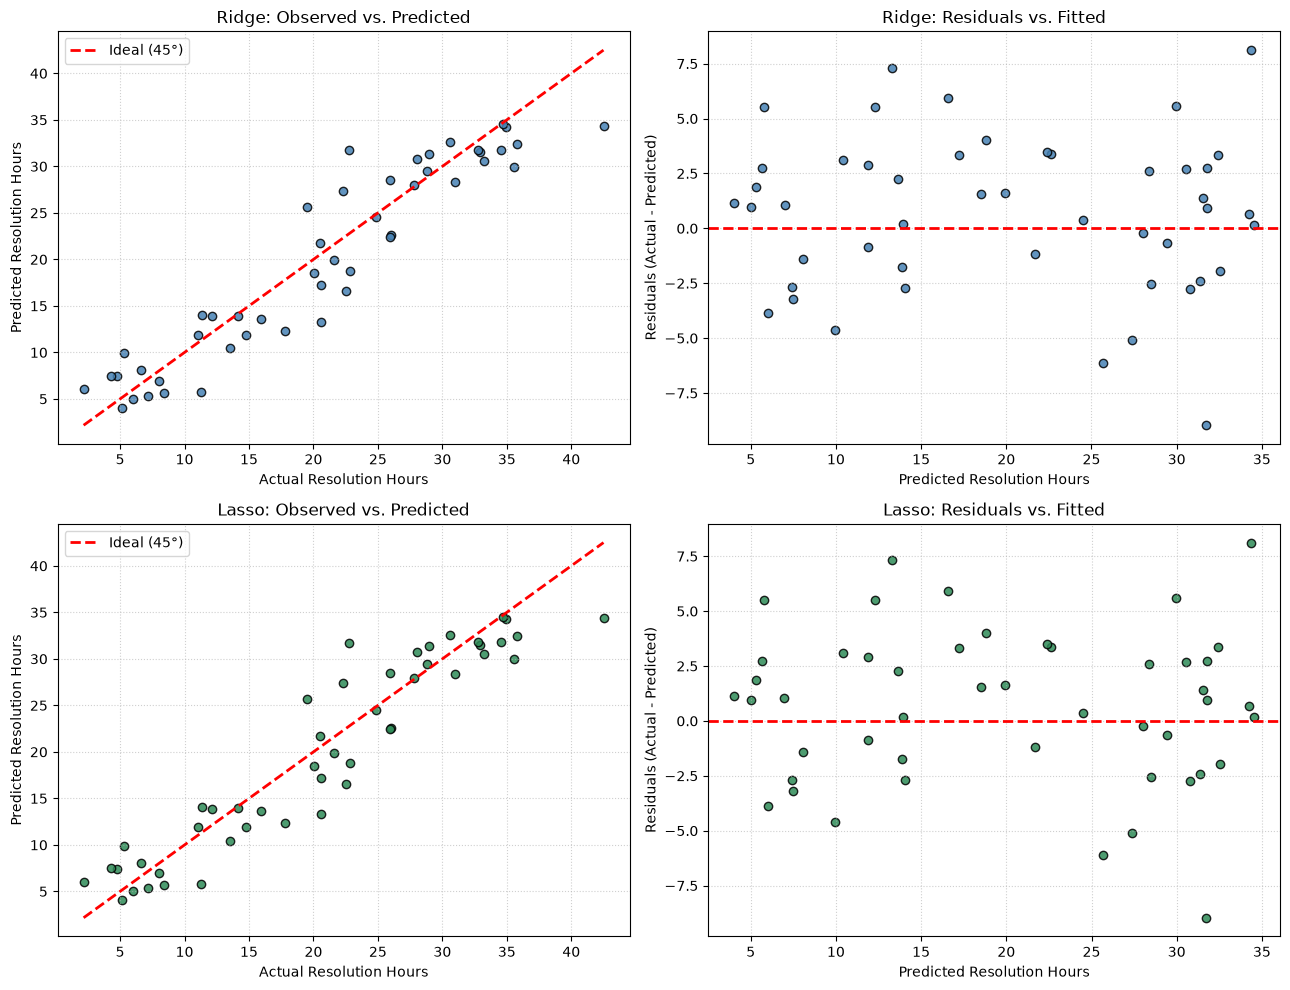

In [14]:
# Generate predictions
preds_ridge = ridge_pipe.predict(X_test)
resids_ridge = y_test - preds_ridge

preds_lasso = lasso_pipe.predict(X_test)
resids_lasso = y_test - preds_lasso

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# --- Model 1: Ridge ---
# 1. Observed vs Predicted
axes[0, 0].scatter(y_test, preds_ridge, color="steelblue", alpha=0.85, edgecolors="k")
axes[0, 0].plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Ideal (45°)"
)
axes[0, 0].set_title("Ridge: Observed vs. Predicted")
axes[0, 0].set_xlabel("Actual Resolution Hours")
axes[0, 0].set_ylabel("Predicted Resolution Hours")
axes[0, 0].legend()
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

# 2. Residual Plot
axes[0, 1].scatter(preds_ridge, resids_ridge, color="steelblue", alpha=0.85, edgecolors="k")
axes[0, 1].axhline(0, color="red", linestyle="--", lw=2)
axes[0, 1].set_title("Ridge: Residuals vs. Fitted")
axes[0, 1].set_xlabel("Predicted Resolution Hours")
axes[0, 1].set_ylabel("Residuals (Actual - Predicted)")
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

# --- Model 2: Lasso ---
# 3. Observed vs Predicted
axes[1, 0].scatter(y_test, preds_lasso, color="seagreen", alpha=0.85, edgecolors="k")
axes[1, 0].plot(
    [y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2, label="Ideal (45°)"
)
axes[1, 0].set_title("Lasso: Observed vs. Predicted")
axes[1, 0].set_xlabel("Actual Resolution Hours")
axes[1, 0].set_ylabel("Predicted Resolution Hours")
axes[1, 0].legend()
axes[1, 0].grid(True, linestyle=":", alpha=0.6)

# 4. Residual Plot
axes[1, 1].scatter(preds_lasso, resids_lasso, color="seagreen", alpha=0.85, edgecolors="k")
axes[1, 1].axhline(0, color="red", linestyle="--", lw=2)
axes[1, 1].set_title("Lasso: Residuals vs. Fitted")
axes[1, 1].set_xlabel("Predicted Resolution Hours")
axes[1, 1].set_ylabel("Residuals (Actual - Predicted)")
axes[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Diagnostic Plots (Observed vs. Predicted & Residuals)
If the residual points form a "U" or inverted "U" shape around the horizontal zero line, the linear assumption misses non-linear effects (such as the quadratic benefits of Degree 2 discovered earlier).
If the residuals fan out as predicted hours grow larger, the variance of the error is non-constant (errors are larger for long, difficult tickets).
 Look for isolated points far off the diagonal line or far away from the $[-3\sigma, +3\sigma]$ residual band.

Optimal Regularization Strength (alpha): 1.2328
Final Test MAE:  2.9991 hours
Final Test RMSE: 3.7200 hours
Final Test R²:   0.8742



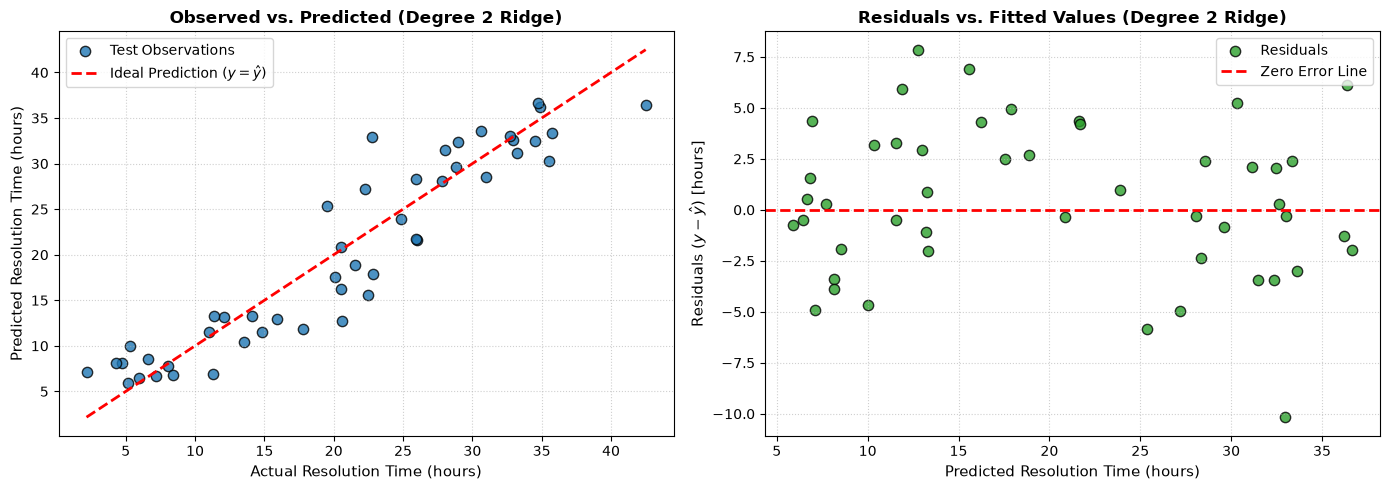

In [16]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# 1. Setup 5-fold CV and search space for Ridge penalty
cv = KFold(n_splits=5, shuffle=True, random_state=42)
alpha_grid = np.logspace(-3, 3, 100)

# 2. Build and fit the chosen Degree 2 + Ridge pipeline
final_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    RidgeCV(alphas=alpha_grid, cv=cv, scoring="neg_mean_squared_error"),
)
final_model.fit(X_train, y_train)

# 3. Evaluate on the untouched test set
y_pred_test = final_model.predict(X_test)
residuals = y_test - y_pred_test

selected_alpha = final_model.named_steps["ridgecv"].alpha_
mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

print(f"Optimal Regularization Strength (alpha): {selected_alpha:.4f}")
print(f"Final Test MAE:  {mae_test:.4f} hours")
print(f"Final Test RMSE: {rmse_test:.4f} hours")
print(f"Final Test R²:   {r2_test:.4f}\n")

# 4. Generate Diagnostic Plots (Observed vs Predicted & Residual Plot)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Observed vs Predicted
ax1.scatter(
    y_test,
    y_pred_test,
    color="#1f77b4",
    edgecolor="black",
    alpha=0.8,
    s=55,
    label="Test Observations",
)
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
ax1.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label=r"Ideal Prediction ($y = \hat{y}$)",
)
ax1.set_title(
    "Observed vs. Predicted (Degree 2 Ridge)", fontsize=12, fontweight="bold"
)
ax1.set_xlabel("Actual Resolution Time (hours)", fontsize=11)
ax1.set_ylabel("Predicted Resolution Time (hours)", fontsize=11)
ax1.legend(frameon=True)
ax1.grid(True, linestyle=":", alpha=0.6)

# Plot B: Residuals vs Predicted
ax2.scatter(
    y_pred_test,
    residuals,
    color="#2ca02c",
    edgecolor="black",
    alpha=0.8,
    s=55,
    label="Residuals",
)
ax2.axhline(0, color="red", linestyle="--", lw=2, label="Zero Error Line")
ax2.set_title(
    "Residuals vs. Fitted Values (Degree 2 Ridge)",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Predicted Resolution Time (hours)", fontsize=11)
ax2.set_ylabel(r"Residuals ($y - \hat{y}$) [hours]", fontsize=11)
ax2.legend(frameon=True)
ax2.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

Chosen ModelDegree 2 Polynomial Regression with Standardized Ridge Regularization ($L_2$).Evidence Supporting the Choice: Superior Cross-Validation Metrics: In 5-fold cross-validation on the training set, Degree 2 achieved the highest mean $R^2$ (0.8437) and lowest RMSE (3.8325), outperforming both the standard linear model (Degree 1, $R^2 = 0.8382$) and the cubic model (Degree 3, $R^2 = 0.8407$).Realistic Problem Modeling: Degree 2 introduces an interaction term (complexity_score × team_experience_years) and diminishing returns curves ($x^2$). This accounts for the real-world operational dynamic where experienced staff mitigate high complexity more effectively than juniors. Regularization Safeguard: Adding Ridge ($L_2$) shrinkage controls multicollinearity between raw features and their squared/interaction terms, avoiding the high variance and parameter instability observed when expanding to Degree 3.
Further Data & Operational Checks NeededUpstream Feature Collection: Even with non-linear terms, 12–15% of the variance remains unexplained. Gathering upstream categorical metadata available at ticket creation—such as system architecture domain (e.g., database vs. frontend), intake severity tag, and intake timestamp (time of day / day of week)—would improve early forecasts.Log-Target Transformation: If the residual plot exhibits mild heteroscedasticity (a widening error fan on longer tickets), training the model on $\log(\text{resolution\_hours})$ via TransformedTargetRegressor should be tested to maintain uniform percentage error.Intake Leakage Audits: Ensure periodic audits confirm complexity_score is assigned strictly during initial triage rather than modified retrospectively after developers encounter roadblocks.

In [17]:
# 1. Extract feature names generated by PolynomialFeatures
poly_features = final_model.named_steps["polynomialfeatures"].get_feature_names_out(
    X_train.columns
)

# 2. Extract learned Ridge coefficients and intercept
standardized_coefs = final_model.named_steps["ridgecv"].coef_
intercept = final_model.named_steps["ridgecv"].intercept_

# 3. Create a clean summary table sorted by absolute impact
coef_df = pd.DataFrame({
    "Feature Term": poly_features,
    "Standardized Coefficient": standardized_coefs,
    "Absolute Impact": np.abs(standardized_coefs),
}).sort_values(by="Absolute Impact", ascending=False).reset_index(drop=True)

print(f"Model Intercept (Mean Target Response): {intercept:.4f} hours\n")
print("--- Standardized Coefficients (Degree 2 Ridge) ---")
print(coef_df.to_string(index=False))

Model Intercept (Mean Target Response): 19.0570 hours

--- Standardized Coefficients (Degree 2 Ridge) ---
                          Feature Term  Standardized Coefficient  Absolute Impact
                      complexity_score                  5.908279         5.908279
                    complexity_score^2                  3.739521         3.739521
complexity_score team_experience_years                 -0.888448         0.888448
                 team_experience_years                 -0.680451         0.680451
               team_experience_years^2                  0.133579         0.133579


Because StandardScaler scaled every polynomial term to have a standard deviation of 1.0 prior to fitting:Direct Relative Importance: The larger the absolute coefficient value, the more influential that term is in predicting resolution time.Positive vs. Negative Weights:Positive (+): Increases predicted resolution time as the term grows (e.g., higher complexity_score).Negative (-): Reduces predicted resolution time as the term grows (e.g., higher team_experience_years).The Interaction Term (complexity_score * team_experience_years): If this coefficient is negative, it confirms that a veteran team dampens the delay caused by high complexity tickets even more than their base experience would suggest.